# Reintento ante un fallo de conexión del LLM

Esta mejora surge de una **pregunta que me hizo el profesor durante la exposición**:

> *¿Qué harías si hay un fallo de conexión al tratar de usar el modelo del LLM?*

La respuesta implementada es: **si la primera llamada falla, reintentar hasta 3 veces y, si el error persiste, decírselo al usuario con un mensaje claro** en lugar de mostrar un traceback.

En este notebook se muestra la estrategia, su implementación en el código del agente y cuatro casos de prueba:

1. un modelo simulado que falla dos veces y responde en el tercer intento;
2. una llamada real a ChatGPT (`gpt-4o-mini`) con una **API key inválida** (error 401, sin consumir tokens);
3. una llamada real con la **API key verdadera** del `.env`, que devuelve error 429 por falta de créditos (tampoco consume tokens);
4. una **API key vacía** en el `.env`: un error de configuración que se detecta al arrancar, sin traceback.

> La API key real nunca se muestra: se lee desde `.env` (excluido del repositorio) y el helper la redacta en cualquier mensaje.

## 1. Estrategia

La lógica quedó en el código de producción, no solo en este notebook:

| Archivo | Cambio |
| :-- | :-- |
| `src/capazeta/config.py` | `LLM_MAX_RETRIES=3` y `LLM_RETRY_DELAY=1.0` configurables por `.env` |
| `src/capazeta/llm.py` | `invoke_with_retry()`: reintenta errores de modelo/red con **backoff exponencial** (1 s, 2 s, 4 s) y lanza `LLMConnectionError` con un mensaje presentable |
| `src/capazeta/graph/nodes.py` | los tres nodos que invocan al LLM pasan por el helper |
| `src/capazeta/main.py` | la CLI captura `LLMConnectionError` y lo muestra con `ui.print_error()` (sin traceback) |

Se reintentan `ModelError` (categoría agnóstica del proveedor que abarca errores de conexión, timeout, rate limit y autenticación de LangChain) y los errores nativos `ConnectionError` / `TimeoutError`. Los errores de código (por ejemplo un `ValueError` en el prompt) **no** se reintentan: se propagan de inmediato.

Para que la demostración sea rápida se inyecta `sleep=lambda _: None` y un callback `on_retry` que imprime cada intento; en producción se usan los valores por defecto de espera.

In [1]:
from langchain_core.exceptions import ModelConnectionError
from capazeta.llm import LLMConnectionError, invoke_with_retry, _redactar


class ModeloQueFalla:
    """Modelo de prueba: falla las primeras `veces` llamadas y luego responde."""

    def __init__(self, veces):
        self.veces = veces
        self.llamadas = 0

    def invoke(self, mensajes):
        self.llamadas += 1
        if self.llamadas <= self.veces:
            raise ModelConnectionError("Connection timed out (simulado)")
        return "Éxito: la respuesta llegó en el tercer intento."


def registrar(intento, espera, exc):
    print(f"  intento {intento} falló → espera de {espera:.2f}s | {_redactar(str(exc))}")


modelo = ModeloQueFalla(veces=2)
print("CASO A · modelo simulado que falla 2 veces")
respuesta = invoke_with_retry(
    modelo,
    ["¿qué técnica MITRE corresponde a fuerza bruta?"],
    max_retries=3,
    base_delay=0.01,
    sleep=lambda _: None,
    on_retry=registrar,
)
print("Llamadas totales:", modelo.llamadas)
print("Resultado:", respuesta)

CASO A · modelo simulado que falla 2 veces
  intento 1 falló → espera de 0.01s | Connection timed out (simulado)
  intento 2 falló → espera de 0.02s | Connection timed out (simulado)
Llamadas totales: 3
Resultado: Éxito: la respuesta llegó en el tercer intento.


## 2. ChatGPT con API key inválida (401, sin gasto)

Se usa `openai:gpt-4o-mini` con una clave falsa. La request llega al proveedor, devuelve `401 Incorrect API key provided` y **no consume tokens**. Los reintentos internos del SDK de OpenAI se desactivan (`max_retries=0`) para que el único mecanismo sea el nuestro.

El mensaje final ya está redactado: la clave ficticia se reemplaza por `<REDACTADO>`.

In [2]:
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI

gpt_invalido = ChatOpenAI(
    model="gpt-4o-mini",
    api_key="sk-invalida-para-prueba",
    max_retries=0,
    request_timeout=15,
)

print("CASO B · API key inválida")
try:
    invoke_with_retry(
        gpt_invalido,
        [HumanMessage(content="Decí hola")],
        max_retries=3,
        base_delay=0.1,
        sleep=lambda _: None,
        on_retry=registrar,
    )
except LLMConnectionError as exc:
    print("\nMensaje que ve el usuario:")
    print(exc)

CASO B · API key inválida


  intento 1 falló → espera de 0.10s | Error code: 401 - {'error': {'message': 'Incorrect API key provided: <REDACTADO>***********ueba. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'code': 'invalid_api_key', 'param': None}, 'status': 401}


  intento 2 falló → espera de 0.20s | Error code: 401 - {'error': {'message': 'Incorrect API key provided: <REDACTADO>***********ueba. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'code': 'invalid_api_key', 'param': None}, 'status': 401}



Mensaje que ve el usuario:
No se pudo conectar con el modelo de lenguaje después de 3 intentos. Revisá tu conexión y la configuración de la API key, o intentá de nuevo en unos minutos. Detalle: Error code: 401 - {'error': {'message': 'Incorrect API key provided: <REDACTADO>***********ueba. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'code': 'invalid_api_key', 'param': None}, 'status': 401}


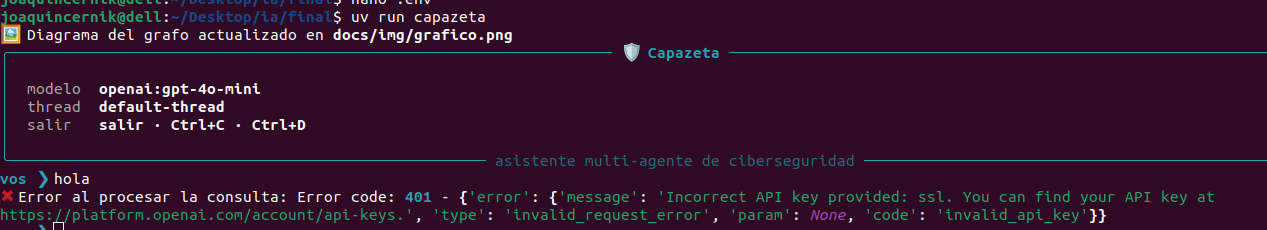

## 3. Llamada real con la API key del `.env` (429 por falta de créditos)

Acá sí se usa la clave verdadera, que se lee desde `.env` (archivo ignorado por Git) y **no se imprime**. Como la cuenta se quedó sin créditos, OpenAI devuelve `429 credit_balance_exhausted`; tampoco consume tokens.

Nota de honestidad: un error de falta de créditos es **permanente**, así que en producción lo ideal sería no reintentarlo. Se reintenta igual en esta demostración para ejercitar el mismo camino que un corte de red transitorio.

In [ ]:
import os
from pathlib import Paacion_RAG_ampliacion_dataset   
joaquincernik@dell:~/Desktop/ia/fith

from dotenv import load_dotenv


def encontrar_env():
    """Busca el .env desde cualquier directorio de ejecución."""
    actual = Path.cwd()
    for candidato in [actual, *actual.parents]:
        if (candidato / ".env").exists():
            return candidato / ".env"
    return None


ruta_env = encontrar_env()
if ruta_env:
    load_dotenv(dotenv_path=ruta_env)
clave = os.getenv("OPENAI_API_KEY")
print("CASO C · llamada real con la API key configurada")
print("API key presente:", bool(clave))

if not clave:
    print("No hay OPENAI_API_KEY configurada; se omite la llamada real.")
else:
    gpt_real = ChatOpenAI(model="gpt-4o-mini", temperature=0, max_retries=0, request_timeout=15)
    try:
        invoke_with_retry(
            gpt_real,
            [HumanMessage(content="Decí hola")],
            max_retries=3,
            base_delay=0.2,
            sleep=lambda _: None,
            on_retry=registrar,
        )
    except LLMConnectionError as exc:
        print("\nMensaje que ve el usuario:")
        print(exc)

CASO C · llamada real con la API key configurada
API key presente: True | valor: <REDACTADO>


  intento 1 falló → espera de 0.20s | Error code: 429 - {'error': {'message': 'You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.', 'type': 'insufficient_quota', 'param': None, 'code': 'credit_balance_exhausted'}}


  intento 2 falló → espera de 0.40s | Error code: 429 - {'error': {'message': 'You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.', 'type': 'insufficient_quota', 'param': None, 'code': 'credit_balance_exhausted'}}



Mensaje que ve el usuario:
No se pudo conectar con el modelo de lenguaje después de 3 intentos. Revisá tu conexión y la configuración de la API key, o intentá de nuevo en unos minutos. Detalle: Error code: 429 - {'error': {'message': 'You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.', 'type': 'insufficient_quota', 'param': None, 'code': 'credit_balance_exhausted'}}


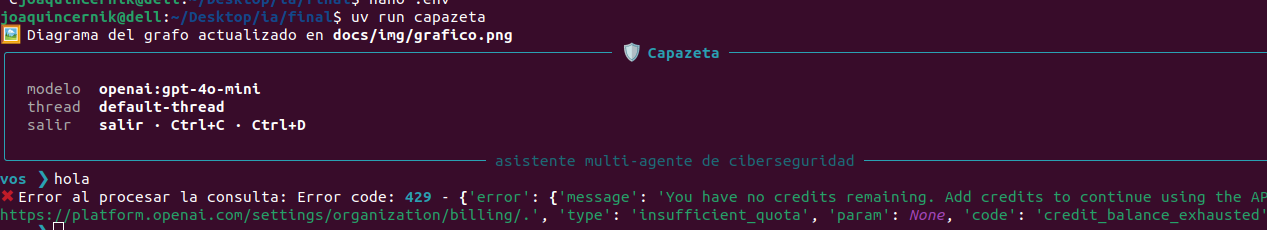

## 4. Lo que ve el usuario en la CLI

`main.py` captura `LLMConnectionError` antes que cualquier otra excepción, así que el bucle interactivo sigue vivo y la persona puede volver a intentar su consulta. No se muestra el traceback ni la API key.

Los tests unitarios de [`tests/test_llm_retry.py`](../tests/test_llm_retry.py) cubren éxito inmediato, recuperación en el tercer intento, agotamiento de reintentos con redacción de secretos, propagación de errores no reintentables y la validación de credenciales (key vacía y salida limpia de la CLI). La sección 5 muestra este último caso.

**Resumen:** ante un fallo de conexión del LLM se reintentan hasta 3 veces con espera exponencial; si persiste, se informa al usuario con un mensaje accionable. Si la key del proveedor está vacía, el error es de configuración: se avisa al arrancar y se sale sin traceback. Esa es la respuesta a la pregunta del docente en la exposición.

In [4]:
from capazeta import ui

print("CASO D · salida en la CLI")
ui.print_error(str(LLMConnectionError(3, "429 insufficient_quota")))

CASO D · salida en la CLI


✖ No se pudo conectar con el modelo de lenguaje después de 3 intentos. Revisá tu conexión y la configuración de la 
API key, o intentá de nuevo en unos minutos. Detalle: 429 insufficient_quota

---

## 5. API key vacía en el `.env`: error de configuración, no de conexión

Los casos anteriores son fallos de **conexión o autenticación** contra el proveedor: por eso se reintentan hasta 3 veces. Hay un caso distinto que también surgió en la exposición: dejar `OPENAI_API_KEY=` vacía en el `.env` con `MODEL_NAME=openai:...`.

Antes del arreglo, el error aparecía **antes de entrar a `main()`**: `main.py` importaba `build_graph` a nivel de módulo y `nodes.py:13` ejecuta `llm = get_llm()` al importar. El `try/except` del bucle interactivo nunca veía este error:

```text
  File ".../src/capazeta/graph/nodes.py", line 13, in <module>
    llm = get_llm()
  File ".../src/capazeta/llm.py", line 102, in get_llm
    return init_chat_model(...)
openai.OpenAIError: Missing credentials. Please pass an `api_key`, `workload_identity`,
`admin_api_key`, or set the `OPENAI_API_KEY` or `OPENAI_ADMIN_KEY` environment variable.
```

`invoke_with_retry()` no puede ayudar acá: todavía no hay ninguna llamada al modelo. Es un error de **configuración**, así que la CLI debe detectarlo **al arrancar**, mostrar un mensaje accionable y terminar sin traceback.

In [1]:
import os
import re
import subprocess
import sys

# Simulamos el campo vacío del .env sin modificar el archivo ni imprimir claves.
entorno = os.environ.copy()
entorno.update(
    {
        "MODEL_NAME": "openai:gpt-4o-mini",
        "OPENAI_API_KEY": "",
        "COLUMNS": "200",
    }
)
resultado = subprocess.run(
    [sys.executable, "-m", "capazeta.main"],
    env=entorno,
    input="",
    capture_output=True,
    text=True,
    timeout=60,
)
salida = re.sub(r"\x1b\[[0-9;]*m", "", resultado.stdout + resultado.stderr).strip()

print("CASO E · OPENAI_API_KEY vacía al arrancar la CLI")
print("Código de salida:", resultado.returncode)
print("Salida:")
print(salida)
print("¿Mostró traceback?:", "Traceback" in salida)
print("¿Menciona la variable faltante?:", "OPENAI_API_KEY" in salida)

CASO E · OPENAI_API_KEY vacía al arrancar la CLI
Código de salida: 1
Salida:
✖ Falta la variable OPENAI_API_KEY en el entorno/.env para usar el modelo openai:gpt-4o-mini. Configurá la key del proveedor y volvé a ejecutar.
¿Mostró traceback?: False
¿Menciona la variable faltante?: True


In [2]:
import os

from capazeta.llm import LLMConfigurationError, validar_credenciales

# El kernel tiene la key real cargada desde .env; la vaciamos solo dentro del
# proceso del notebook y la restauramos en `finally` para no alterar nada.
valor_original = os.environ.get("OPENAI_API_KEY")
os.environ["OPENAI_API_KEY"] = ""
print("Validación directa de la configuración:")
try:
    validar_credenciales("openai:gpt-4o-mini")
except LLMConfigurationError as exc:
    print("Tipo de error:", type(exc).__name__)
    print("Mensaje:", exc)
finally:
    if valor_original is None:
        os.environ.pop("OPENAI_API_KEY", None)
    else:
        os.environ["OPENAI_API_KEY"] = valor_original

Validación directa de la configuración:
Tipo de error: LLMConfigurationError
Mensaje: Falta la variable OPENAI_API_KEY en el entorno/.env para usar el modelo openai:gpt-4o-mini. Configurá la key del proveedor y volvé a ejecutar.


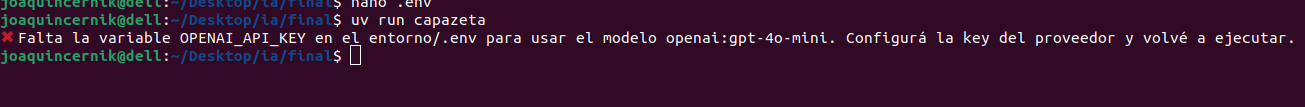

### Respuesta correcta

Con la key vacía, la CLI muestra una sola línea y termina:

```text
✖ Falta la variable OPENAI_API_KEY en el entorno/.env para usar el modelo openai:gpt-4o-mini. Configurá la key del proveedor y volvé a ejecutar.
```

- **No hay traceback** y el proceso sale con código `1` (falló la configuración).
- **No se reintenta**: no hay una llamada al proveedor que pueda recuperarse.
- **No se muestra ni se guarda ninguna clave**; el `.env` real queda intacto.

El mismo chequeo cubre a los otros proveedores del catálogo: `groq:…` exige `GROQ_API_KEY` y `google_genai:…` exige `GOOGLE_API_KEY`. Los tests de [`tests/test_llm_retry.py`](../tests/test_llm_retry.py) verifican los tres casos y la salida limpia de la CLI.